# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

In [23]:
class Heap:
    def __init__(self):
        # self.arreglo[0] es -INF, este como tal no hace parte del arbol
        self.arreglo = [float('-inf')]

    def _percolate_up(self, i):
        # mientras estemos debajo de la raiz 
        # y el nodo sea menor que su padre , sube
        while i // 2 > 0:
            if self.arreglo[i] < self.arreglo[i // 2]:
                # intercambiamos el nodo con su padre
                self.arreglo[i], self.arreglo[i // 2] = self.arreglo[i // 2], self.arreglo[i]
            # actualizamos nuestra posición a la del padre
            i = i // 2

    def _percolate_down(self, i):
        # Mientras el nodo tenga al menos un hijo izquierdo
        while (i * 2) <= len(self.arreglo) - 1:
            mc = self._min_child(i) # Calculamos cuál de los dos hijos es el menor
            if self.arreglo[i] > self.arreglo[mc]:
                # Si el nodo actual es mayor que su hijo menor, los intercambiamos (lo hundimos)
                self.arreglo[i], self.arreglo[mc] = self.arreglo[mc], self.arreglo[i]
            # Actualizamos nuestra posición a la del hijo
            i = mc

    def _min_child(self, i):
        # Si el nodo NO tiene hijo derecho, devolvemos de una el izquierdo
        if i * 2 + 1 > len(self.arreglo) - 1:
            return i * 2
        else:
            # Si tiene ambos hijos, comparamos sus valores y devolvemos el índice del mas chiquito
            if self.arreglo[i * 2] < self.arreglo[i * 2 + 1]:
                return i * 2
            else:
                return i * 2 + 1

    def insert(self, valor):
        # 1. metemos el valor nuevo al final del arreglo
        self.arreglo.append(valor)
        # 2. lo hacemos ir hacia arriba para que quede en su posición correcta
        self._percolate_up(len(self.arreglo) - 1)

    def remove_smallest(self):
        # Si el heap está vacío (solo tiene el -INF), no hay nada que sacar
        if len(self.arreglo) == 1:
            return None
        
        # 1. Guardamos el valor más pequeño, que siempre es la raíz
        retval = self.arreglo[1]
        
        # 2. Cogemos el último elemento de la lista y lo ponemos en la raíz
        self.arreglo[1] = self.arreglo[len(self.arreglo) - 1]
        self.arreglo.pop() # Borramos ese último elemento que acabamos de mover
        
        # 3. Hundimos esa nueva raíz hasta que recupere el orden del Min Heap
        self._percolate_down(1)
        
        return retval

    def build_heap(self, lista):
        # Este es el Punto 2[cite: 1]. Ahorita le metemos la lógica para construirlo de un solo golpe.
        pass

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

In [24]:
def build_heap(self, lista):
    # Reiniciamos el arreglo con el -INF y le pegamos la lista completa
    # Usamos lista[:] para hacer una copia y no dañar la original por error
    self.arreglo = [float('-inf')] + lista[:]
    
    # 2. Calculamos la mitad de la lista (ahí están los últimos nodos que tienen hijos)
    i = len(lista) // 2
    
    # 3. Vamos retrocediendo uno por uno hasta llegar a la raíz (posición 1)
    while i > 0:
        self._percolate_down(i) # Hundimos al papá si es mayor que sus hijos
        i = i - 1

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

In [29]:
%%writefile heap.py
import matplotlib.pyplot as plt
import networkx as nx

class Heap:
    def __init__(self):
        self.arreglo = [float('-inf')]

    def _percolate_up(self, i):
        while i // 2 > 0:
            if self.arreglo[i] < self.arreglo[i // 2]:
                self.arreglo[i], self.arreglo[i // 2] = self.arreglo[i // 2], self.arreglo[i]
            i = i // 2

    def _percolate_down(self, i):
        while (i * 2) <= len(self.arreglo) - 1:
            mc = self._min_child(i)
            if self.arreglo[i] > self.arreglo[mc]:
                self.arreglo[i], self.arreglo[mc] = self.arreglo[mc], self.arreglo[i]
            i = mc

    def _min_child(self, i):
        if i * 2 + 1 > len(self.arreglo) - 1:
            return i * 2
        else:
            if self.arreglo[i * 2] < self.arreglo[i * 2 + 1]:
                return i * 2
            else:
                return i * 2 + 1

    def insert(self, valor, imagen=False):
        self.arreglo.append(valor)
        self._percolate_up(len(self.arreglo) - 1)
        if imagen:
            self._dibujar()

    def remove_smallest(self, imagen=False):
        if len(self.arreglo) == 1:
            return None
        retval = self.arreglo[1]
        self.arreglo[1] = self.arreglo[len(self.arreglo) - 1]
        self.arreglo.pop()
        self._percolate_down(1)
        if imagen:
            self._dibujar()
        return retval

    def build_heap(self, lista, imagen=False):
        self.arreglo = [float('-inf')] + lista[:]
        i = len(lista) // 2
        while i > 0:
            self._percolate_down(i)
            i = i - 1
        if imagen:
            self._dibujar()

    def _dibujar(self):
        if len(self.arreglo) <= 1:
            return
            
        G = nx.Graph()
        
        for i in range(1, len(self.arreglo)):
            G.add_node(i, label=str(self.arreglo[i]))
            if i // 2 > 0:
                G.add_edge(i // 2, i)

        def calcular_posiciones(indice, x, y, x_offset):
            pos = {}
            if indice < len(self.arreglo):
                pos[indice] = (x, y)
                pos.update(calcular_posiciones(indice * 2, x - x_offset, y - 1, x_offset / 2))
                pos.update(calcular_posiciones(indice * 2 + 1, x + x_offset, y - 1, x_offset / 2))
            return pos

        posiciones = calcular_posiciones(1, x=0, y=0, x_offset=1)
        etiquetas = nx.get_node_attributes(G, 'label')
        
        plt.figure(figsize=(6, 4))
        nx.draw(G, pos=posiciones, labels=etiquetas, with_labels=True, 
                node_size=1200, node_color="#4FC3F7", 
                font_size=12, font_weight="bold")
        plt.margins(0.1)
        plt.show()

Overwriting heap.py


## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

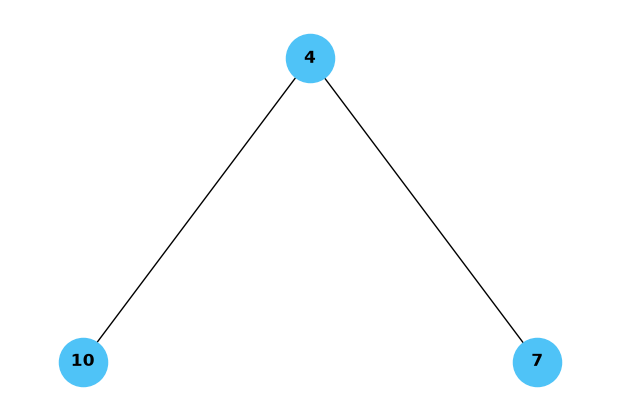

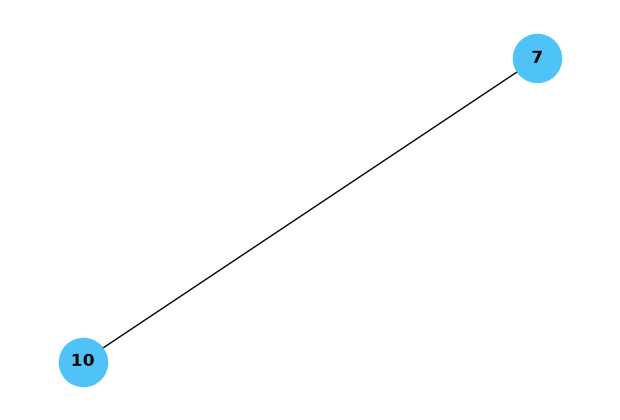

4

In [32]:
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [27]:
%%writefile heap.py
class Heap:

    def __init__(self):
        self.arreglo = [float('-inf')]

Overwriting heap.py


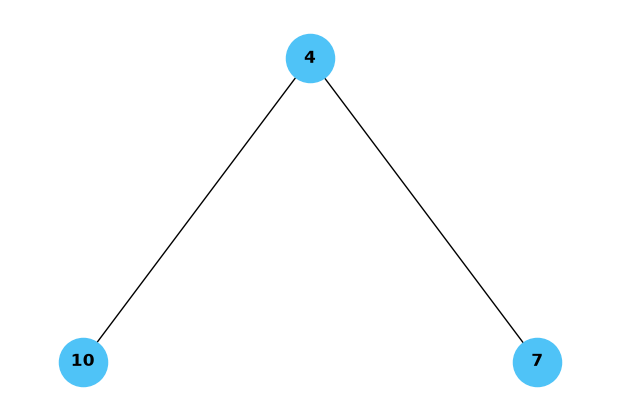

In [31]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)